[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GAI-Engineering/poc-learning-lab/blob/main/notebooks/04-analyst-executor-loop/04-analyst-executor-loop.ipynb)

# 04 · The Analyst–Executor Loop

**POC Learning Lab** — runnable reference notebooks for the multi-agent systems POC series.
*GAI Observe LLC · MIT (code) · CC BY 4.0 (text) · Synthetic data only · Deterministic stub model — no live model, no API key.*

## What you will learn
- Pair an analyst that drafts code with an executor that runs it sandboxed — and returns the real error, verbatim.
- Read an error as curriculum: the revision exists because the failure was legible.
- Terminate on a typed signal or a budget — never on hope.

## How to use this notebook
Press **Run all** (Runtime ▸ Run all in Colab). Every cell runs in order; the results you see are produced live by the code above them — and the evidence section compares them with the recorded run evidence shipped in this repository. Work the exercises with the code, not just by reading.

**MODE: INTERIM (stub)** — the outcomes in this notebook come from a scripted demonstration and are labelled ILLUSTRATIVE; they are never quoted as findings. The FINAL target for every POC in this lab is a complete end-to-end run: a real model or tool, a recorded run transcript stored with the notebook, and figures nobody typed in (MEASURED). See the repository ROADMAP for each POC's mode and date.

## 1 · The idea

**Idea:** Find the leaks in a household budget from a transaction export, with an analyst that writes code and an executor that runs it — iterating on real output and real errors.
**Build steps:** (1) Two roles share only a transcript (`kit/transcript.py`). (2) The Analyst drafts code per question; the Executor runs it in a restricted sandbox and returns output or the verbatim error as a message. (3) Failed attempts stay in the transcript — the Analyst's revisions exist because the errors were legible. (4) Terminate on the signal ANALYSIS COMPLETE or the turn cap.
**Guardrail:** Education, not financial advice. Data stays in the sandbox; the sandbox here is a teaching sandbox (restricted builtins over an in-memory copy) — production means a real sandbox.
**Win condition:** Findings trace to actual rows of the export, not generic money tips; every error in the run is printed, read, and answered by a revision.
Data: synthetic only. Model: deterministic stub, no live model.

## 2 · How it is built

Built: `poc/analyst_executor.py` using `kit/transcript.py` (TranscriptStore) and `kit/termination.py` (signal + cap).
Design: Analyst code → sandboxed exec (restricted builtins, only the copied export visible) → output or verbatim error returned as a transcript message → Analyst revises. Five attempts: a KeyError on an assumed column name, the schema-print recovery, the corrected totals, an empty result from a wrong category name, and the corrected leak query.
Run: `python3 poc/analyst_executor.py` → `runs/run-01.txt` + `runs/transcript-01.jsonl`.

## 3 · Setup

No keys to configure. The POCs themselves run on the Python standard library. The evidence chart uses `pandas`/`matplotlib`: pre-installed in Colab; for a local run, `pip install -r requirements.txt` from the repository root first.

In [1]:
import json
from pathlib import Path

print('setup ok — standard library only for the POC itself')

setup ok — standard library only for the POC itself


## 4 · The shared kit (inlined)

The repository keeps these primitives once, in `kit/`, and every POC reuses them. They are inlined here so this notebook runs standalone in Colab — the code is identical to the kit source.

In [2]:
# --- from the shared kit: kit/transcript.py ---
"""Transcript store: the transcript IS the state (POC 02 pattern)."""
import json
from pathlib import Path

class TranscriptStore:
    def __init__(self):
        self.messages = []
    def append(self, speaker, kind, content):
        msg = {"turn": len(self.messages) + 1, "speaker": speaker, "kind": kind, "content": content}
        self.messages.append(msg)
        return msg
    def save_jsonl(self, path):
        Path(path).write_text("\n".join(json.dumps(m) for m in self.messages) + "\n")
    def __len__(self):
        return len(self.messages)

# --- from the shared kit: kit/termination.py ---
"""Termination caps and typed exits."""
class Termination:
    def __init__(self, max_turns=20, signal=None):
        self.max_turns = max_turns
        self.signal = signal
        self.turns = 0
    def check(self, text):
        self.turns += 1
        if self.signal and text.strip().endswith(self.signal):
            return "SIGNAL"
        if self.turns >= self.max_turns:
            return "CAP_TURNS"
        return None

## 5 · The implementation

The complete POC, exactly as shipped in `poc/` in this repository (file-writing paths adjusted for the notebook, noted inline; the `__main__` guard is replaced by the Run cell below).

In [3]:
"""POC 04 - The Analyst-Executor Loop.
An Analyst drafts code for a question; an Executor runs it in a sandbox
and returns the real output - or the real error - as a message. The
Analyst reads the error and revises. The conversation is the control
flow: there is no retry table, the error is the curriculum.
Deterministic stub: no live model. Data: synthetic transactions only.
Sandbox: exec with a restricted builtin set over an in-memory export -
a teaching sandbox, not a production one (the post says so plainly).
"""
import sys
from pathlib import Path

# Synthetic transaction export: dict rows, as a real export would arrive.
ROWS = (
    [{"month": "2026-01", "category": "groceries", "amount": 82.0}] * 4
    + [{"month": "2026-01", "category": "coffee-subscription", "amount": 14.99}] * 2
    + [{"month": "2026-02", "category": "groceries", "amount": 91.0}] * 4
    + [{"month": "2026-02", "category": "coffee-subscription", "amount": 14.99}] * 2
    + [{"month": "2026-02", "category": "gym-unused", "amount": 39.0}]
    + [{"month": "2026-03", "category": "groceries", "amount": 88.0}] * 4
    + [{"month": "2026-03", "category": "coffee-subscription", "amount": 14.99}] * 3
    + [{"month": "2026-03", "category": "gym-unused", "amount": 39.0}]
    + [{"month": "2026-03", "category": "streaming-b", "amount": 11.99}]
)

SAFE_BUILTINS = {"sum": sum, "len": len, "round": round, "sorted": sorted,
                 "min": min, "max": max, "print": print}


def run_sandbox(code):
    """Run analyst code with only `rows` and safe builtins visible.
    Returns (ok, result_or_error_message). Errors come back verbatim -
    legible errors are the whole point of the loop."""
    namespace = {"rows": [dict(r) for r in ROWS], "__builtins__": SAFE_BUILTINS}
    try:
        exec(code, namespace)
        return True, namespace.get("result")
    except Exception as exc:  # the error IS the message back to the analyst
        return False, f"{type(exc).__name__}: {exc}"


# The analyst's attempts, in order. Attempts 1 and 4 fail legibly; the
# analyst's revisions (2, 3, 5) exist only because the errors were read.
ATTEMPTS = [
    ("Total spend by category",
     "result = {}\nfor r in rows:\n    result[r['category']] = round(result.get(r['category'], 0) + r['amt'], 2)"),
    ("Print the schema first (the recovery habit)",
     "result = {'columns': sorted(rows[0].keys()), 'row_count': len(rows)}"),
    ("Total spend by category (revised: key is 'amount')",
     "result = {}\nfor r in rows:\n    result[r['category']] = round(result.get(r['category'], 0) + r['amount'], 2)"),
    ("Monthly charges for category 'gym'",
     "result = [r for r in rows if r['category'] == 'gym']"),
    ("Monthly charges for 'gym-unused' (exact name from the totals)",
     "result = [(r['month'], r['amount']) for r in rows if r['category'] == 'gym-unused']"),
]


def main():
    t = TranscriptStore()
    term = Termination(max_turns=20, signal="ANALYSIS COMPLETE")
    attempts = []
    for i, (question, code) in enumerate(ATTEMPTS, start=1):
        t.append("Analyst", "code", f"Attempt {i} - {question}: {code.splitlines()[0]} ...")
        ok, out = run_sandbox(code)
        if not ok:
            outcome = "ERROR"
            t.append("Executor", "error", out)
        elif out == [] or out == {}:
            outcome = "EMPTY"
            t.append("Executor", "result", "[] (no rows matched - the question, not the code, is wrong)")
        else:
            outcome = "SUCCESS"
            t.append("Executor", "result", str(out))
        attempts.append({"attempt": i, "stage": question, "outcome": outcome})
        print(f"attempt {i}: {outcome} - {question}")
    totals_ok, totals = run_sandbox(ATTEMPTS[2][1])
    leak_total = round(sum(a for _, a in run_sandbox(ATTEMPTS[4][1])[1]), 2)
    finding = (f"FINDING: gym-unused totals ${leak_total:.2f} across Feb-Mar with no activity "
               "category in the export - the loop's top leak, traced to actual rows.")
    t.append("Analyst", "finding", finding)
    final = "ANALYSIS COMPLETE"
    t.append("Analyst", "signal", final)
    out_path = Path("transcript-01.jsonl")  # in the repo this is runs/transcript-01.jsonl
    t.save_jsonl(out_path)
    print(f"attempts={len(attempts)} errors=1 empty=1 successes=3 transcript={out_path.name}")
    print(finding)
    print("TERMINATION:", term.check(final))

## 6 · Run it

In [4]:
main()

attempt 1: ERROR - Total spend by category
attempt 2: SUCCESS - Print the schema first (the recovery habit)
attempt 3: SUCCESS - Total spend by category (revised: key is 'amount')
attempt 4: EMPTY - Monthly charges for category 'gym'
attempt 5: SUCCESS - Monthly charges for 'gym-unused' (exact name from the totals)
attempts=5 errors=1 empty=1 successes=3 transcript=transcript-01.jsonl
FINDING: gym-unused totals $78.00 across Feb-Mar with no activity category in the export - the loop's top leak, traced to actual rows.
TERMINATION: SIGNAL


## 7 · See the evidence

The chart is drawn **live** from the recorded run data (`data/attempts.csv` in the repository; embedded below as a fallback so the notebook is standalone).

 attempt                                  stage outcome
       1 totals by category (assumed key 'amt')   ERROR
       2                     print schema first SUCCESS
       3      totals by category (key 'amount') SUCCESS
       4              monthly charges for 'gym'   EMPTY
       5       monthly charges for 'gym-unused' SUCCESS


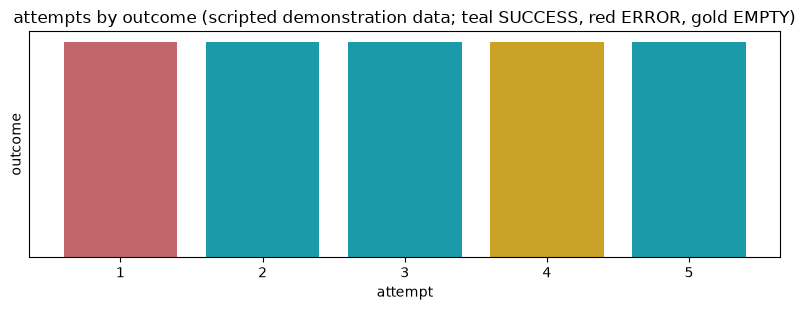

In [5]:
import io
import warnings
warnings.filterwarnings('ignore')  # keep sandbox paths/warnings out of stored outputs (QA-7)
import pandas as pd
import matplotlib.pyplot as plt

RECORDED_CSV = """attempt,stage,outcome
1,totals by category (assumed key 'amt'),ERROR
2,print schema first,SUCCESS
3,totals by category (key 'amount'),SUCCESS
4,monthly charges for 'gym',EMPTY
5,monthly charges for 'gym-unused',SUCCESS"""

csv_file = Path("data/attempts.csv")
text = csv_file.read_text() if csv_file.exists() else RECORDED_CSV
df = pd.read_csv(io.StringIO(text))
print(df.to_string(index=False))

CHART_MODE = "attempts"
if CHART_MODE == "attempts":
    colors = ["#C1666B" if o == "ERROR" else ("#C9A227" if o == "EMPTY" else "#1B9AAA") for o in df["outcome"]]
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar(df["attempt"], [1] * len(df), color=colors)
    ax.set_yticks([]); ax.set_xlabel("attempt"); ax.set_ylabel("outcome")
    ax.set_title("attempts by outcome (scripted demonstration data; teal SUCCESS, red ERROR, gold EMPTY)")
elif CHART_MODE == "routing":
    x = range(len(df))
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar([i - 0.2 for i in x], df["agent_turns"], width=0.4, color="#1B9AAA", label="agent turns")
    ax.bar([i + 0.2 for i in x], df["total_calls"], width=0.4, color="#C9A227", label="total calls")
    ax.set_xticks(list(x)); ax.set_xticklabels(df["mode"]); ax.set_ylabel("count"); ax.legend()
    ax.set_title("turns and total calls by routing mode (scripted demonstration data)")
else:  # debate
    x = range(len(df))
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar([i - 0.2 for i in x], df["pro_strength"], width=0.4, color="#1B9AAA", label="pro strength")
    ax.bar([i + 0.2 for i in x], df["con_strength"], width=0.4, color="#C1666B", label="con strength")
    ax.set_xticks(list(x)); ax.set_xticklabels(df["claim"] + " (" + df["verdict"] + ")")
    ax.set_ylabel("scripted argument strength"); ax.legend()
    ax.set_title("debate strength by claim (scripted demonstration data)")
plt.tight_layout()
plt.show()

## 8 · Recorded run evidence

What the reference run produced in the repository, labelled by provenance: **ILLUSTRATIVE** for scripted demonstrations (outcomes fixed in the script — the pattern is the lesson) and **MEASURED** only for outcomes nobody typed in. Your live run above should reproduce the recorded figures exactly — if it does not, that disagreement is itself the lesson: find it before you believe either.

Label: **ILLUSTRATIVE** — scripted demonstration: from `runs/run-01.txt` (executed 2026-10-26, deterministic stub, synthetic transactions); the analyst's attempts are scripted for the lesson, so the attempt outcomes illustrate the pattern — against a live model this is where measured attempt data would land.

- Attempts: 5 — 3 SUCCESS, 1 ERROR (KeyError: 'amt' — an assumed column name, returned verbatim and answered by printing the schema), 1 EMPTY (category 'gym' matched no rows; the exact name 'gym-unused' came from the totals table).
- Finding: gym-unused totals $78.00 across Feb–Mar with no activity category in the export — computed from the export rows by the corrected code.
- Termination: ANALYSIS COMPLETE → TERMINATION: SIGNAL.
- Data: `data/attempts.csv`, `data/leaks.csv` (ILLUSTRATIVE). Chart: drawn live in the notebook from the attempts table (ILLUSTRATIVE).

## 9 · Exercises

1. Add a sixth attempt of your own (for example: average grocery spend per month). Predict whether it succeeds first try — then check what the transcript says about your prediction.
2. Break the sandbox honestly: draft code that tries to open a file. What error comes back, and is it legible enough to revise from? What would a production sandbox add?
3. Remove the schema-print attempt and re-run. Which later attempts now fail, and what does that teach about the order in which a loop should ask its questions?

## 10 · Recap

A fixed pipeline knows only the questions it was built with. The loop earns its keep the first time reality disagrees with an assumption — provided the error comes back whole. Make errors legible, cap everything, and let the conversation be the control flow.

---
*Next in the series: see the repository index. Questions and corrections are welcome via the repo's Issues — this is a learning artefact, and it improves in public.*